# Cadeia de Markov: o caminho de um exame no laboratório municipal

**Ponderada · Módulo 8 · Inteli** — Débora Nogueira

Este notebook modela, com uma cadeia de Markov de tempo discreto, a jornada de um exame laboratorial dentro de um laboratório de saúde municipal, desde o momento em que a requisição é criada até o laudo ser liberado ao paciente (ou a requisição ser cancelada). O contexto é inspirado no módulo de Laboratório do e-Cidade, sistema de gestão pública com o qual o grupo trabalha neste módulo, mas **todas as probabilidades são hipotéticas**, definidas para fins de estudo, e nenhum dado real de município é usado.

O roteiro do notebook segue a ordem do vídeo: (1) o problema, (2) a matriz de transição, (3) a simulação e (4) a leitura dos resultados, comparando o que a simulação mostra com o que a teoria das cadeias absorventes prevê.

## 1. O problema

Quem já fez exame de sangue num posto de saúde conhece o percurso: o médico pede o exame, o paciente vai até o posto para a coleta, a amostra segue para o laboratório, alguém analisa, um bioquímico confere o resultado e só então o laudo é liberado. O que quase ninguém vê são os **desvios** desse caminho: a amostra que chega hemolisada e precisa ser recoletada, o resultado que o bioquímico devolve para reanálise, o paciente que nunca aparece e tem a requisição cancelada.

A pergunta que a gestão do laboratório quer responder é simples de enunciar e difícil de responder de cabeça: **em quanto tempo, em média, um exame requisitado vira laudo liberado? E que fração dos exames se perde no caminho?**

Uma cadeia de Markov encaixa bem aqui porque o processo tem duas características:

- **Estados bem definidos**: em cada dia, o exame está em exatamente uma etapa do fluxo.
- **Falta de memória (propriedade de Markov)**: o que acontece amanhã depende só da etapa em que o exame está hoje, e não de como ele chegou até ali. É como um jogo de tabuleiro: a próxima casa depende do dado e da casa em que você está, não do caminho que você fez até ela.

A segunda hipótese é uma simplificação, e ela é discutida no fim do notebook.

### Estados

| Estado | Significado | Tipo |
|---|---|---|
| **Requisitado** | Requisição criada, aguardando a coleta da amostra | transitório |
| **Coletado** | Amostra coletada, em transporte ou triagem | transitório |
| **Em análise** | Amostra sendo processada no setor técnico | transitório |
| **Em conferência** | Resultado digitado, aguardando validação do bioquímico | transitório |
| **Liberado** | Laudo liberado ao paciente | **absorvente** |
| **Cancelado** | Requisição cancelada (paciente não compareceu, pedido inválido) | **absorvente** |

Um estado **absorvente** é uma "porta de saída": quando o exame chega nele, não sai mais. Por isso esta é uma **cadeia de Markov absorvente**.

**Passo de tempo:** 1 dia útil. A cada dia, o exame ou permanece na etapa em que está (fila, espera) ou avança, volta ou é cancelado.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(42)  # semente fixa: resultados reprodutíveis

## 2. A matriz de transição

A matriz $P$ guarda, na linha $i$ e coluna $j$, a probabilidade de um exame que **hoje** está no estado $i$ estar **amanhã** no estado $j$. Cada linha soma 1, porque o exame precisa estar em algum lugar no dia seguinte.

As probabilidades abaixo foram definidas a partir de um raciocínio sobre o fluxo, não de dados reais:

- **Requisitado**: 30% dos exames ainda esperam a coleta no dia seguinte (o paciente agenda para outro dia), 65% são coletados e 5% são cancelados.
- **Coletado**: 82% chegam à análise no dia seguinte, 10% ficam na triagem e **8% voltam para Requisitado** porque a amostra foi rejeitada (hemólise, volume insuficiente, identificação errada) e precisa de recoleta.
- **Em análise**: 60% terminam a análise e vão para conferência, 35% continuam na fila do setor e **5% voltam para Requisitado** porque a amostra se mostrou inviável durante o processamento.
- **Em conferência**: 72% são liberados, 20% esperam o bioquímico e **8% voltam para análise** porque o resultado foi questionado (valor fora do esperado, necessidade de repetição).
- **Liberado** e **Cancelado**: ficam neles para sempre (probabilidade 1 na diagonal).

In [2]:
estados = ["Requisitado", "Coletado", "Em análise", "Em conferência", "Liberado", "Cancelado"]
abrev   = ["REQ", "COL", "ANA", "CONF", "LIB", "CANC"]

P = np.array([
    #  REQ   COL   ANA   CONF  LIB   CANC
    [0.30, 0.65, 0.00, 0.00, 0.00, 0.05],  # Requisitado
    [0.08, 0.10, 0.82, 0.00, 0.00, 0.00],  # Coletado
    [0.05, 0.00, 0.35, 0.60, 0.00, 0.00],  # Em análise
    [0.00, 0.00, 0.08, 0.20, 0.72, 0.00],  # Em conferência
    [0.00, 0.00, 0.00, 0.00, 1.00, 0.00],  # Liberado   (absorvente)
    [0.00, 0.00, 0.00, 0.00, 0.00, 1.00],  # Cancelado  (absorvente)
])

assert np.allclose(P.sum(axis=1), 1), "Cada linha precisa somar 1"
pd.DataFrame(P, index=estados, columns=estados).style.format("{:.2f}").background_gradient(cmap="Blues", axis=None)

,Requisitado,Coletado,Em análise,Em conferência,Liberado,Cancelado
Requisitado,0.30,0.65,0.00,0.00,0.00,0.05
Coletado,0.08,0.10,0.82,0.00,0.00,0.00
Em análise,0.05,0.00,0.35,0.60,0.00,0.00
Em conferência,0.00,0.00,0.08,0.20,0.72,0.00
Liberado,0.00,0.00,0.00,0.00,1.00,0.00
Cancelado,0.00,0.00,0.00,0.00,0.00,1.00


### Diagrama de estados

O diagrama mostra a mesma matriz como um grafo: cada seta é uma transição com probabilidade maior que zero. As setas vermelhas são os **retrabalhos** (recoleta e reanálise), que são justamente o que torna o tempo total difícil de estimar de cabeça.

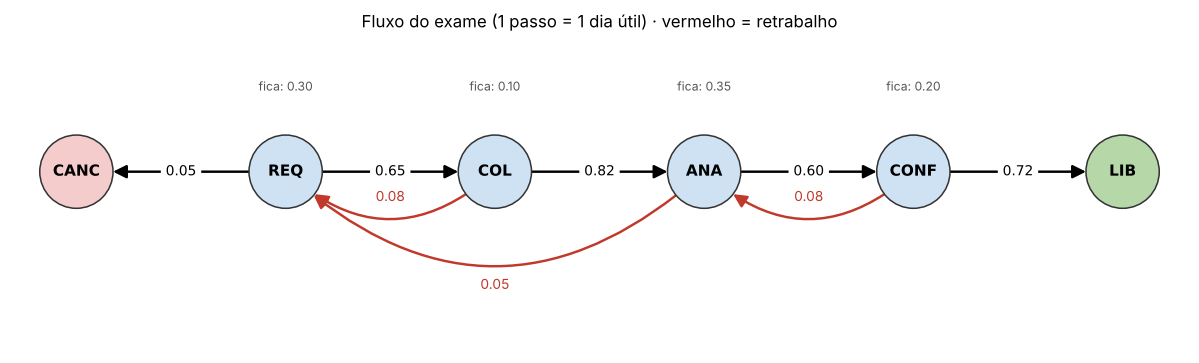

In [3]:
G = nx.DiGraph()
for i, a in enumerate(abrev):
    for j, b in enumerate(abrev):
        if P[i, j] > 0 and i != j:
            G.add_edge(a, b, w=P[i, j])

pos = {"REQ": (0, 0), "COL": (1.6, 0), "ANA": (3.2, 0), "CONF": (4.8, 0), "LIB": (6.4, 0), "CANC": (-1.6, 0)}
retrabalho = {("COL", "REQ"), ("ANA", "REQ"), ("CONF", "ANA")}
cores_no = ["#cfe2f3"] * 4 + ["#b6d7a8", "#f4cccc"]

fig, ax = plt.subplots(figsize=(11, 3.4))
nx.draw_networkx_nodes(G, pos, nodelist=abrev, node_color=cores_no, node_size=2300, edgecolors="#333", ax=ax)
nx.draw_networkx_labels(G, pos, font_size=10, font_weight="bold", ax=ax)
normais = [e for e in G.edges if e not in retrabalho]
nx.draw_networkx_edges(G, pos, edgelist=normais, node_size=2300, arrowsize=18, width=1.6, ax=ax)
nx.draw_networkx_edges(G, pos, edgelist=list(retrabalho), node_size=2300, arrowsize=18, width=1.6,
                       edge_color="#c0392b", connectionstyle="arc3,rad=-0.45", ax=ax)
rot = {e: f"{G.edges[e]['w']:.2f}" for e in G.edges}
nx.draw_networkx_edge_labels(G, pos, edge_labels={e: v for e, v in rot.items() if e not in retrabalho}, font_size=9, ax=ax)
for (a, b) in retrabalho:
    xa, ya = pos[a]; xb, yb = pos[b]
    ax.text((xa + xb) / 2, (ya - 0.13 if abs(xa - xb) < 2 else ya - 0.52), f"{P[abrev.index(a), abrev.index(b)]:.2f}", color="#c0392b", ha="center", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none"))
for i, a in enumerate(abrev[:4]):
    x, y = pos[a]
    ax.text(x, y + 0.36, f"fica: {P[i, i]:.2f}", ha="center", fontsize=8, color="#555")
ax.set_title("Fluxo do exame (1 passo = 1 dia útil) · vermelho = retrabalho", fontsize=11)
ax.set_ylim(-0.8, 0.6); ax.set_xlim(-2.1, 6.9); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. Simulação

A simulação faz exatamente o que a matriz descreve: pega um exame em **Requisitado** e, a cada dia, "joga um dado viciado" com as probabilidades da linha do estado atual para decidir para onde ele vai. Repete até o exame cair em **Liberado** ou **Cancelado**. Fazendo isso para 10.000 exames, obtemos uma distribuição de resultados, e não um único caminho.

### 3.1 Uma trajetória, para ganhar intuição

In [4]:
def simular_exame(P, inicio=0, max_dias=365):
    estado, caminho = inicio, [inicio]
    while estado < 4 and len(caminho) <= max_dias:   # 4 e 5 são absorventes
        estado = rng.choice(len(P), p=P[estado])
        caminho.append(estado)
    return caminho

for k in range(5):
    cam = simular_exame(P)
    print(f"Exame {k+1} ({len(cam)-1:2d} dias): " + " → ".join(abrev[s] for s in cam))

Exame 1 ( 4 dias): REQ → COL → ANA → CONF → LIB
Exame 2 ( 2 dias): REQ → REQ → CANC
Exame 3 ( 5 dias): REQ → COL → ANA → ANA → CONF → LIB
Exame 4 ( 4 dias): REQ → COL → ANA → CONF → LIB
Exame 5 ( 7 dias): REQ → REQ → COL → REQ → COL → ANA → CONF → LIB


### 3.2 Monte Carlo com 10.000 exames

In [5]:
N_EXAMES = 10_000
dias, destino, recoletas, reanalises = [], [], [], []

for _ in range(N_EXAMES):
    cam = simular_exame(P)
    dias.append(len(cam) - 1)
    destino.append(abrev[cam[-1]])
    pares = list(zip(cam[:-1], cam[1:]))
    recoletas.append(sum(1 for a, b in pares if b == 0 and a in (1, 2)))
    reanalises.append(sum(1 for a, b in pares if a == 3 and b == 2))

sim = pd.DataFrame({"dias": dias, "destino": destino, "recoletas": recoletas, "reanalises": reanalises})

resumo = pd.Series({
    "Exames liberados (%)":                 100 * (sim.destino == "LIB").mean(),
    "Exames cancelados (%)":                100 * (sim.destino == "CANC").mean(),
    "Dias até o fim, média":                sim.dias.mean(),
    "Dias até liberar, média (só LIB)":     sim.loc[sim.destino == "LIB", "dias"].mean(),
    "Dias até liberar, mediana":            sim.loc[sim.destino == "LIB", "dias"].median(),
    "Dias até liberar, percentil 90":       sim.loc[sim.destino == "LIB", "dias"].quantile(0.9),
    "Exames com ao menos 1 recoleta (%)":   100 * (sim.recoletas > 0).mean(),
    "Exames com ao menos 1 reanálise (%)":  100 * (sim.reanalises > 0).mean(),
}).round(2)
resumo.to_frame("Simulação")

,Simulação
Exames liberados (%),91.77
Exames cancelados (%),8.23
"Dias até o fim, média",5.86
"Dias até liberar, média (só LIB)",6.21
"Dias até liberar, mediana",6.00
"Dias até liberar, percentil 90",9.00
Exames com ao menos 1 recoleta (%),15.12
Exames com ao menos 1 reanálise (%),8.88


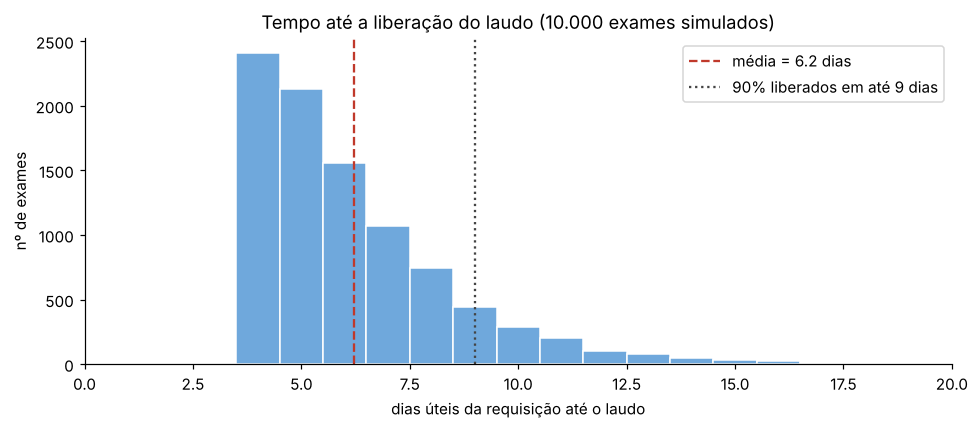

In [6]:
lib = sim.loc[sim.destino == "LIB", "dias"]
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(lib, bins=range(0, lib.max() + 2), color="#6fa8dc", edgecolor="white", align="left")
ax.axvline(lib.mean(), color="#c0392b", ls="--", label=f"média = {lib.mean():.1f} dias")
ax.axvline(lib.quantile(0.9), color="#444", ls=":", label=f"90% liberados em até {lib.quantile(0.9):.0f} dias")
ax.set_xlim(0, 20); ax.set_xlabel("dias úteis da requisição até o laudo"); ax.set_ylabel("nº de exames")
ax.set_title("Tempo até a liberação do laudo (10.000 exames simulados)")
ax.legend(); plt.tight_layout(); plt.show()

### 3.3 Como a "população" de exames se espalha pelos estados ao longo dos dias

Em vez de seguir um exame de cada vez, dá para acompanhar a **distribuição de probabilidade** de um exame estar em cada estado no dia $t$. Partindo de $\pi_0 = [1, 0, 0, 0, 0, 0]$ (todo exame começa requisitado), basta multiplicar pela matriz a cada dia:

$$\pi_{t} = \pi_{t-1} \, P = \pi_0 \, P^t$$

Uma forma intuitiva de ler isso: imagine 100 exames requisitados hoje. $\pi_t$ diz quantos deles, em média, estarão em cada etapa daqui a $t$ dias.

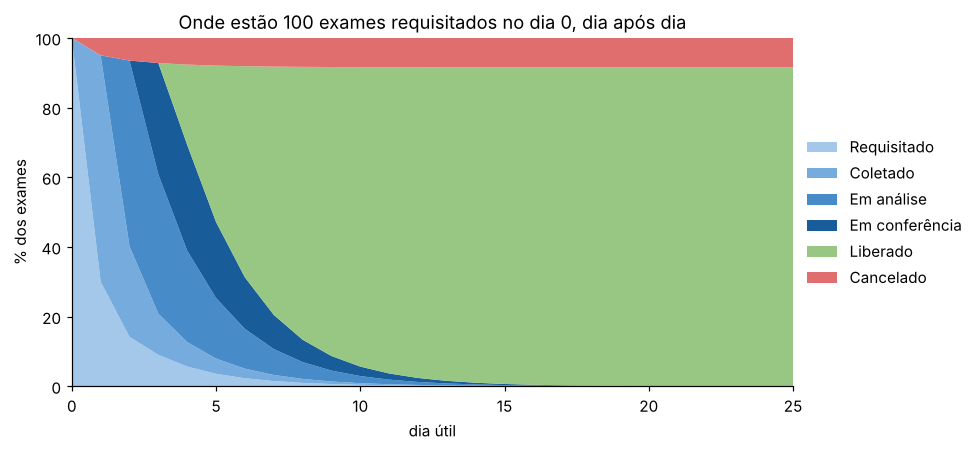

,Requisitado,Coletado,Em análise,Em conferência,Liberado,Cancelado
dia 1,30.0,65.0,0.0,0.0,0.0,5.0
dia 3,9.0,11.8,40.0,32.0,0.0,7.2
dia 5,3.6,4.4,17.4,21.8,44.9,7.9
dia 10,0.4,0.5,2.0,2.7,86.0,8.4
dia 15,0.0,0.1,0.2,0.3,90.9,8.4
dia 20,0.0,0.0,0.0,0.0,91.5,8.4


In [7]:
T = 25
pi = np.zeros((T + 1, len(P))); pi[0, 0] = 1
for t in range(1, T + 1):
    pi[t] = pi[t - 1] @ P

cores = ["#9fc5e8", "#6fa8dc", "#3d85c6", "#0b5394", "#93c47d", "#e06666"]
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.stackplot(range(T + 1), pi.T * 100, labels=estados, colors=cores, alpha=0.95)
ax.set_xlim(0, T); ax.set_ylim(0, 100)
ax.set_xlabel("dia útil"); ax.set_ylabel("% dos exames")
ax.set_title("Onde estão 100 exames requisitados no dia 0, dia após dia")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout(); plt.show()

pd.DataFrame(pi[[1, 3, 5, 10, 15, 20]] * 100, index=[f"dia {d}" for d in [1, 3, 5, 10, 15, 20]],
             columns=estados).round(1)

## 4. Conferindo a simulação com a teoria (cadeia absorvente)

Numa cadeia absorvente, não faz sentido procurar uma distribuição estacionária "interessante": no longo prazo, **todo** exame termina em Liberado ou Cancelado. As perguntas úteis passam a ser outras, e a teoria responde a elas sem simular nada.

Reorganizando a matriz com os estados transitórios primeiro, ela fica em blocos:

$$P = \begin{bmatrix} Q & R \\ 0 & I \end{bmatrix}$$

- $Q$ (4×4): transições entre estados transitórios
- $R$ (4×2): transições de transitórios para absorventes

A peça central é a **matriz fundamental** $N = (I - Q)^{-1}$. A intuição: $N_{ij}$ é o número esperado de dias que um exame que começou em $i$ passa no estado $j$ antes de sair do sistema. Ela soma todos os "retornos" possíveis ($I + Q + Q^2 + \dots$), incluindo os desvios de recoleta e reanálise.

A partir dela:

- **Tempo esperado até a absorção**: $t = N \mathbf{1}$ (soma das linhas de $N$)
- **Probabilidade de terminar em cada estado absorvente**: $B = N R$

In [8]:
Q = P[:4, :4]
R = P[:4, 4:]
N = np.linalg.inv(np.eye(4) - Q)
t_abs = N.sum(axis=1)
B = N @ R

print("Matriz fundamental N (dias esperados em cada estado, por estado de partida):")
display(pd.DataFrame(N, index=estados[:4], columns=estados[:4]).round(3))

display(pd.DataFrame({
    "Dias esperados até sair": t_abs,
    "P(Liberado)": B[:, 0],
    "P(Cancelado)": B[:, 1],
}, index=estados[:4]).round(3))

Matriz fundamental N (dias esperados em cada estado, por estado de partida):


,Requisitado,Coletado,Em análise,Em conferência
Requisitado,1.689,1.220,1.695,1.272
Coletado,0.281,1.314,1.826,1.369
Em análise,0.143,0.103,1.839,1.379
Em conferência,0.014,0.010,0.184,1.388


,Dias esperados até sair,P(Liberado),P(Cancelado)
Requisitado,5.876,0.916,0.084
Coletado,4.790,0.986,0.014
Em análise,3.464,0.993,0.007
Em conferência,1.596,0.999,0.001


In [9]:
comparacao = pd.DataFrame({
    "Teoria (matriz fundamental)": [100 * B[0, 0], 100 * B[0, 1], t_abs[0]],
    "Simulação (10.000 exames)":   [100 * (sim.destino == "LIB").mean(),
                                    100 * (sim.destino == "CANC").mean(),
                                    sim.dias.mean()],
}, index=["Liberados (%)", "Cancelados (%)", "Dias até o fim (média)"]).round(2)
comparacao["Diferença"] = (comparacao.iloc[:, 1] - comparacao.iloc[:, 0]).round(2)
comparacao

,Teoria (matriz fundamental),Simulação (10.000 exames),Diferença
Liberados (%),91.55,91.77,0.22
Cancelados (%),8.45,8.23,-0.22
Dias até o fim (média),5.88,5.86,-0.02


A simulação e a teoria batem com diferença pequena, que é o erro natural de amostragem do Monte Carlo (ele diminui à medida que aumentamos o número de exames simulados). Isso valida a implementação: o código da simulação faz o que a matriz diz.

A leitura da matriz fundamental também mostra **onde o tempo é gasto**. Na primeira linha de $N$, um exame recém-requisitado passa em média cerca de 1,7 dia em **Em análise** e outro 1,7 dia em **Requisitado** (esperando coleta, incluindo as recoletas), contra cerca de 1,2 a 1,3 dia nas demais etapas. A fila do setor técnico e a espera pela coleta são, portanto, as etapas que mais pesam no tempo total do fluxo hipotético.

## 5. E se o laboratório reduzisse as recoletas?

Um uso prático do modelo é testar cenários sem mexer no laboratório real. Suponha um treinamento de coleta que reduza pela metade a rejeição de amostras na triagem (de 8% para 4%), redistribuindo essa probabilidade para o avanço à análise. Quanto o tempo médio cai?

In [10]:
def metricas(P):
    Q, R = P[:4, :4], P[:4, 4:]
    N = np.linalg.inv(np.eye(4) - Q)
    return N.sum(axis=1)[0], (N @ R)[0, 0]

cenarios = {}
cenarios["Atual"] = P.copy()

P_coleta = P.copy(); P_coleta[1, 0] = 0.04; P_coleta[1, 2] = 0.86
cenarios["Recoleta na triagem 8% → 4%"] = P_coleta

P_fila = P.copy(); P_fila[2, 2] = 0.20; P_fila[2, 3] = 0.75
cenarios["Fila da análise 35% → 20%"] = P_fila

res = pd.DataFrame({nome: metricas(M) for nome, M in cenarios.items()},
                   index=["Dias até o fim (média)", "P(Liberado)"]).T
res["P(Liberado)"] *= 100
res = res.rename(columns={"P(Liberado)": "Liberados (%)"}).round(2)
res

,Dias até o fim (média),Liberados (%)
Atual,5.88,91.55
Recoleta na triagem 8% → 4%,5.76,91.92
Fila da análise 35% → 20%,5.50,91.69


No modelo, reduzir a fila da análise corta cerca de 0,4 dia do tempo médio, enquanto reduzir as recoletas na triagem corta cerca de 0,1 dia (embora aumente um pouco a fração de laudos liberados). Os dois cenários não representam esforços equivalentes, então a comparação não diz qual intervenção "vale mais", mas mostra o tipo de pergunta que o modelo ajuda a responder antes de investir: o tempo é mais sensível à fila da análise, coerente com a matriz fundamental.

## 6. Conclusão e limitações

A cadeia de Markov transformou um fluxo que parece linear (requisitar, coletar, analisar, conferir, liberar) em um modelo que leva em conta as filas e os retrabalhos, e permitiu responder às perguntas da gestão com números: quantos dias, em média, um exame leva até o laudo, que fração é cancelada, e qual etapa mais pesa no tempo total. A simulação de Monte Carlo e a solução analítica pela matriz fundamental chegaram aos mesmos valores, o que dá confiança tanto no código quanto na interpretação.

As limitações vêm das próprias hipóteses do modelo:

- **Falta de memória**: na realidade, um exame que já foi recoletado duas vezes tende a ser cancelado com mais facilidade, e um exame parado há muitos dias na fila pode ser priorizado. A cadeia simples ignora esse histórico; uma extensão seria incluir estados como "recoleta 1" e "recoleta 2".
- **Probabilidades constantes**: o modelo assume que a matriz não muda com o dia da semana, a sazonalidade ou a carga do laboratório.
- **Tipo de exame**: um hemograma e uma cultura têm tempos de análise muito diferentes; na prática, haveria uma matriz por tipo de exame.
- **Parâmetros hipotéticos**: com dados reais (o histórico de mudanças de situação dos exames no sistema), as probabilidades poderiam ser **estimadas** contando as transições observadas: $\hat{p}_{ij} = n_{ij} / \sum_k n_{ik}$.